**STEP 1 — Load Baseline Predictions**


The objective of this notebook is not to re-run Mistral-7B.
Instead, the objective is to investigate whether alternative confidence signals derived from option likelihoods can better distinguish between correct and incorrect predictions.

Using the saved baseline outputs ensures:

- reproducibility
- computational efficiency
- direct comparability with previous experiments

Relationship to Previous Notebook

1. Notebook 01 generated:

- baseline accuracy
- confidence scores
- calibration metrics

Notebook 02 investigated:

- selective prediction using those confidence scores

This notebook extends the analysis by constructing new confidence signals from option likelihood information.


**STEP 1.1 — Import Libraries**

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

**STEP 1.2 — Load Baseline Results**

In [ ]:
results_df = pd.read_csv(
    "/content/drive/MyDrive/Dissertation/baseline_option_scores.csv"
)

print("="*70)
print("BASELINE DATASET")
print("="*70)
print(f"Number of records : {len(results_df)}")

BASELINE DATASET
Number of records : 817


**STEP 1.3 — Verify Dataset Structure**

In [ ]:
print("=" * 70)
print("DATASET FEATURES")
print("=" * 70)

for i, column in enumerate(results_df.columns, start=1):
    print(f"{i}. {column}")

DATASET FEATURES
1. question
2. predicted_index
3. true_index
4. confidence
5. correct
6. option_probabilities
7. option_scores
8. predicted_answer
9. true_answer


**STEP 1.4 — Dataset Integrity Check**

In [ ]:
print("=" * 60)
print("MISSING VALUES")
print("=" * 60)

print(
    results_df.isnull().sum()
)

MISSING VALUES
question                0
predicted_index         0
true_index              0
confidence              0
correct                 0
option_probabilities    0
option_scores           0
predicted_answer        0
true_answer             0
dtype: int64


**STEP 1.5 — Baseline Summary Statistics**

In [ ]:
baseline_accuracy = (
    results_df["correct"]
    .astype(int)
    .mean()
)

mean_confidence = (
    results_df["confidence"]
    .mean()
)

print("=" * 60)
print("BASELINE PERFORMANCE SUMMARY")
print("=" * 60)

print(f"{'Dataset Size':<22}: {len(results_df)}")
print(f"{'Baseline Accuracy':<22}: {baseline_accuracy:.4f}")
print(f"{'Mean Confidence':<22}: {mean_confidence:.4f}")

BASELINE PERFORMANCE SUMMARY
Dataset Size          : 817
Baseline Accuracy     : 0.5055
Mean Confidence       : 0.3481


**STEP 1.6 — Confidence Distribution**

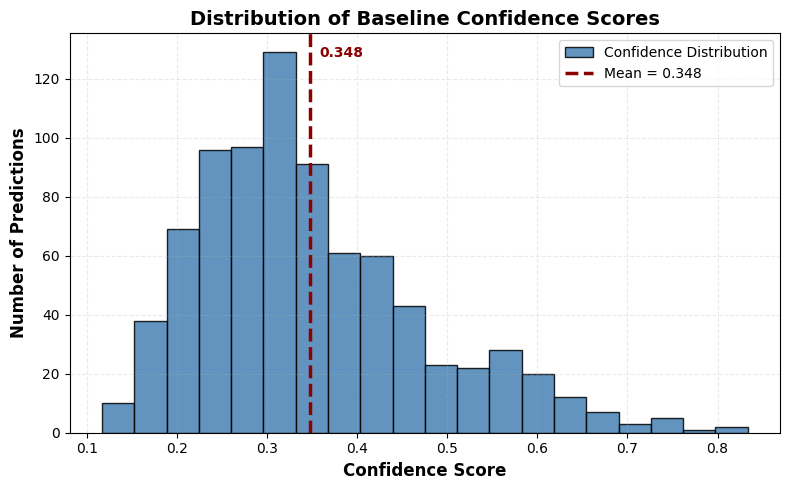

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(
    results_df["confidence"],
    bins=20,
    color="steelblue",
    edgecolor="black",
    linewidth=1,
    alpha=0.85,
    label="Confidence Distribution"
)

plt.axvline(
    mean_confidence,
    color="darkred",
    linestyle="--",
    linewidth=2.5,
    label=f"Mean = {mean_confidence:.3f}"
)

plt.text(
    mean_confidence + 0.01,
    plt.ylim()[1] * 0.94,
    f"{mean_confidence:.3f}",
    color="darkred",
    fontsize=10,
    fontweight="bold"
)

plt.xlabel(
    "Confidence Score",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Number of Predictions",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Distribution of Baseline Confidence Scores",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    alpha=0.25,
    linestyle="--"
)

plt.legend()

plt.tight_layout()

plt.show()

**STEP 1.7 — Confidence by Correctness**

In [ ]:
summary = (

    results_df

    .groupby("correct")

    ["confidence"]

    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])

)

summary.index = [
    "Incorrect",
    "Correct"
]

display(

    summary

    .style

    .background_gradient(
        cmap="Blues"
    )

    .format({

        "mean": "{:.3f}",
        "std": "{:.3f}",
        "min": "{:.3f}",
        "max": "{:.3f}"

    })

)

,mean,std,min,max
Incorrect,0.308,0.104,0.129,0.815
Correct,0.388,0.133,0.117,0.833


**STEP 1.8 — Confidence Boxplot**

/tmp/ipykernel_1533/444819643.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


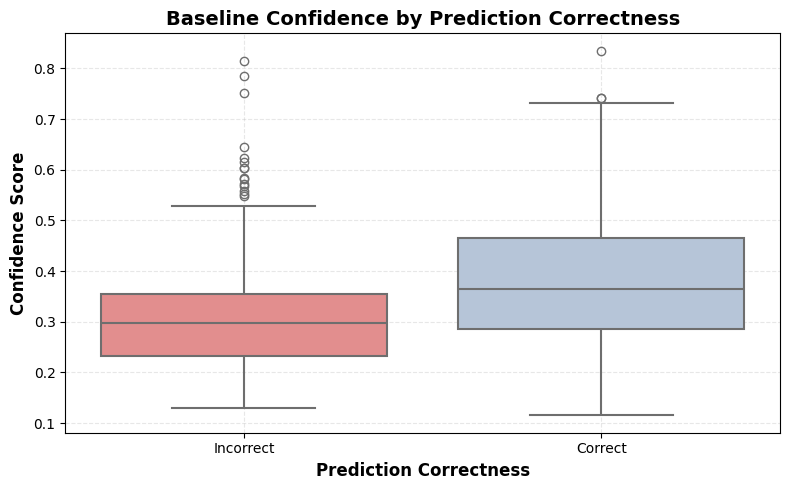

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=results_df,
    x="correct",
    y="confidence",
    palette={
        "False": "lightcoral",
        "True": "lightsteelblue"
    },
    linewidth=1.5
)

plt.xlabel(
    "Prediction Correctness",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Confidence Score",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Baseline Confidence by Prediction Correctness",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(
    [0,1],
    ["Incorrect","Correct"]
)

plt.grid(
    alpha=0.30,
    linestyle="--"
)

plt.tight_layout()

plt.show()

**STEP 1.9 — Save Notebook Metadata**

In [ ]:
import json

metadata = {

    "input_file":
        "baseline_predictions.csv",

    "rows":
        int(len(results_df)),

    "accuracy":
        float(baseline_accuracy)

}

with open(

    "option_likelihood_metadata.json",

    "w"

) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

Although the baseline confidence score provides useful information about prediction reliability, the observed overlap between correct and incorrect predictions suggests that confidence alone is an imperfect indicator of correctness. This motivates the investigation of alternative uncertainty signals derived from the complete answer-option likelihood distribution

**STEP 2 — Construct Option Likelihood Signals**

**STEP 2.1 — Parse Option Probability Data**

In [ ]:
import ast

print("=" * 70)
print("OPTION PROBABILITIES (FIRST SAMPLE)")
print("=" * 70)
print("Example probability distribution")
print(results_df["option_probabilities"].iloc[0])

OPTION PROBABILITIES (FIRST SAMPLE)
Example probability distribution
[0.2187605813534571, 0.3193407309431222, 0.29074266399498105, 0.17115602370843977]


**STEP 2.2 — Compute Entropy**

In [ ]:
def compute_entropy(probs):

    probs = np.array(probs)

    probs = np.clip(
        probs,
        1e-12,
        1
    )

    entropy = -np.sum(
        probs * np.log(probs)
    )

    return entropy


results_df["option_probabilities"] = results_df["option_probabilities"].apply(ast.literal_eval)

results_df["entropy"] = (
    results_df["option_probabilities"]
    .apply(compute_entropy)
)

display(

results_df[["entropy"]]

.head()

.style

.background_gradient(
    cmap="Blues"
)

.format({
    "entropy":"{:.4f}"
})

)


,entropy
0,1.3583
1,1.4857
2,1.3084
3,1.3335
4,1.8567


**STEP 2.3 — Compute Normalised Entropy**

In [ ]:
def compute_normalised_entropy(probs):

    probs = np.array(probs)

    entropy = compute_entropy(
        probs
    )

    max_entropy = np.log(
        len(probs)
    )

    return entropy / max_entropy


results_df["normalised_entropy"] = (
    results_df["option_probabilities"]
    .apply(
        compute_normalised_entropy
    )
)

display(

results_df[
    ["normalised_entropy"]
]

.head()

.style

.background_gradient(
    cmap="Purples"
)

.format({
    "normalised_entropy":"{:.4f}"
})

)

,normalised_entropy
0,0.9798
1,0.9231
2,0.9438
3,0.9619
4,0.9542


**STEP 2.4 — Compute Margin Score**

In [ ]:
def compute_margin(probs):

    probs = sorted(
        probs,
        reverse=True
    )

    return (
        probs[0]
        -
        probs[1]
    )


results_df["margin_score"] = (
    results_df["option_probabilities"]
    .apply(
        compute_margin
    )
)

display(

results_df[
    ["margin_score"]
]

.head()

.style

.background_gradient(
    cmap="Greens"
)

.format({
    "margin_score":"{:.4f}"
})

)

,margin_score
0,0.0286
1,0.2291
2,0.2281
3,0.1460
4,0.1388


**STEP 2.5 — Compute Probability Gap**

In [ ]:
results_df["probability_gap"] = (
    results_df["margin_score"]
)

display(

results_df[
    ["probability_gap"]
]

.head()

.style

.background_gradient(
    cmap="Greens"
)

.format({
    "probability_gap":"{:.4f}"
})

)

print()

print(
    "Margin Score equals Probability Gap:",
    np.allclose(
        results_df["margin_score"],
        results_df["probability_gap"]
    )
)

,probability_gap
0,0.0286
1,0.2291
2,0.2281
3,0.1460
4,0.1388



Margin Score equals Probability Gap: True


In this experiment, probability gap and margin score are mathematically equivalent because both are defined as the difference between the highest and second-highest option probabilities. Both names are retained because different uncertainty estimation literature uses different terminology.

**STEP 2.6 — Create Signal Dataset**

In [ ]:
signal_df = results_df[[
    "confidence",
    "entropy",
    "normalised_entropy",
    "margin_score",
    "probability_gap",
    "correct"
]].copy()

display(

signal_df

.head()

.style

.background_gradient(
    subset=["confidence"],
    cmap="Blues"
)

.background_gradient(
    subset=["entropy","normalised_entropy"],
    cmap="Purples"
)

.background_gradient(
    subset=[
        "margin_score",
        "probability_gap"
    ],
    cmap="Greens"
)

.format({

    "confidence":"{:.3f}",

    "entropy":"{:.3f}",

    "normalised_entropy":"{:.3f}",

    "margin_score":"{:.3f}",

    "probability_gap":"{:.3f}"

})

)

,confidence,entropy,normalised_entropy,margin_score,probability_gap,correct
0,0.319,1.358,0.980,0.029,0.029,False
1,0.410,1.486,0.923,0.229,0.229,True
2,0.430,1.308,0.944,0.228,0.228,True
3,0.385,1.334,0.962,0.146,0.146,True
4,0.295,1.857,0.954,0.139,0.139,True


**STEP 2.7 — Signal Summary Statistics**

In [ ]:
summary_stats = (
    signal_df
    .describe()
)

display(

summary_stats.style

.background_gradient(
    subset=["confidence"],
    cmap="Blues"
)

.background_gradient(
    subset=["entropy", "normalised_entropy"],
    cmap="Purples"
)

.background_gradient(
    subset=["margin_score", "probability_gap"],
    cmap="Greens"
)

.format("{:.4f}")

)

,confidence,entropy,normalised_entropy,margin_score,probability_gap
count,817.0000,817.0000,817.0000,817.0000,817.0000
mean,0.3481,1.4707,0.9452,0.1095,0.1095
std,0.1258,0.3584,0.0564,0.1158,0.1158
min,0.1167,0.4504,0.5854,0.0003,0.0003
25%,0.2573,1.2974,0.9248,0.0249,0.0249
50%,0.3236,1.5060,0.9644,0.0676,0.0676
75%,0.4154,1.7241,0.9843,0.1566,0.1566
max,0.8335,2.5396,1.0000,0.6669,0.6669


In [ ]:
summary_stats.to_csv(
    "option_signal_summary.csv"
)

**STEP 2.8 — Save Signal Dataset**

In [ ]:
signal_df.to_csv(

    "option_likelihood_signals.csv",

    index=False

)

print("=" * 70)
print("SIGNAL DATASET SAVED")
print("=" * 70)

print("File : option_likelihood_signals.csv")

print(f"Rows : {len(signal_df)}")

print(f"Signals : {signal_df.shape[1]}")

SIGNAL DATASET SAVED
File : option_likelihood_signals.csv
Rows : 817
Signals : 6


This step constructed multiple uncertainty signals from the option probability distributions. Unlike baseline confidence, which considers only the selected answer, entropy-based measures capture uncertainty across all answer options, while the margin score and probability gap quantify the separation between the two most likely options. Together, these signals provide a richer representation of predictive uncertainty and form the basis for the comparative evaluation in the following sections.

**STEP 3 — Signal–Correctness Relationship Analysis**

This step evaluates whether the option-likelihood signals constructed in Step 2 are informative indicators of prediction correctness.

The baseline confidence score was originally used as the primary confidence estimate. However, Step 2 introduced additional uncertainty signals derived from the full answer-option probability distribution.

The objective of this step is to determine whether these new signals exhibit stronger relationships with correctness than baseline confidence.

**STEP 3.1 — Prepare Analysis Dataset**

In [ ]:
analysis_df = signal_df.copy()

analysis_df["correct"] = (
    analysis_df["correct"]
    .astype(int)
)

display(
    analysis_df.head().style
    .background_gradient(
        subset=["confidence"],
        cmap="Blues"
    )
    .background_gradient(
        subset=["entropy","normalised_entropy"],
        cmap="Purples"
    )
    .background_gradient(
        subset=["margin_score","probability_gap"],
        cmap="Greens"
    )
)

,confidence,entropy,normalised_entropy,margin_score,probability_gap,correct
0,0.319341,1.358274,0.979788,0.028598,0.028598,0
1,0.410306,1.485724,0.923132,0.229115,0.229115,1
2,0.430482,1.308432,0.943834,0.228116,0.228116,1
3,0.384879,1.333505,0.961921,0.146043,0.146043,1
4,0.294637,1.856746,0.954179,0.138779,0.138779,1


**STEP 3.2 — Pearson Correlation Analysis**

In [ ]:
from scipy.stats import pearsonr

signals = [
    "confidence",
    "entropy",
    "normalised_entropy",
    "margin_score",
    "probability_gap"
]

pearson_results = []

for signal in signals:

    corr, p = pearsonr(
        analysis_df[signal],
        analysis_df["correct"]
    )

    pearson_results.append({
        "Signal": signal,
        "Correlation": corr,
        "P_Value": p
    })

pearson_table = pd.DataFrame(
    pearson_results
)

display(

pearson_table.style

.background_gradient(
    subset=["Correlation"],
    cmap="RdYlGn"
)

.background_gradient(
    subset=["P_Value"],
    cmap="Blues_r"
)

.format({

    "Correlation":"{:.3f}",

    "P_Value":"{:.2e}"

})

)

,Signal,Correlation,P_Value
0,confidence,0.318,1.07e-20
1,entropy,-0.120,6.06e-04
2,normalised_entropy,-0.321,4.91e-21
3,margin_score,0.399,1.41e-32
4,probability_gap,0.399,1.41e-32


**STEP 3.3 — Rank Signals by Correlation Strength**

In [ ]:
pearson_table["Abs_Correlation"] = (
    pearson_table["Correlation"]
    .abs()
)

pearson_table = (
    pearson_table
    .sort_values(
        "Abs_Correlation",
        ascending=False
    )
)

display(

    pearson_table

    .style

    .background_gradient(
        subset=["Correlation"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Abs_Correlation"],
        cmap="Purples"
    )

    .background_gradient(
        subset=["P_Value"],
        cmap="Reds_r"
    )

    .format({

        "Correlation": "{:.3f}",

        "Abs_Correlation": "{:.3f}",

        "P_Value": "{:.3e}"

    })

)

,Signal,Correlation,P_Value,Abs_Correlation
4,probability_gap,0.399,1.409e-32,0.399
3,margin_score,0.399,1.409e-32,0.399
2,normalised_entropy,-0.321,4.909e-21,0.321
0,confidence,0.318,1.074e-20,0.318
1,entropy,-0.120,6.058e-04,0.120


**STEP 3.4 — Correlation Visualisation**

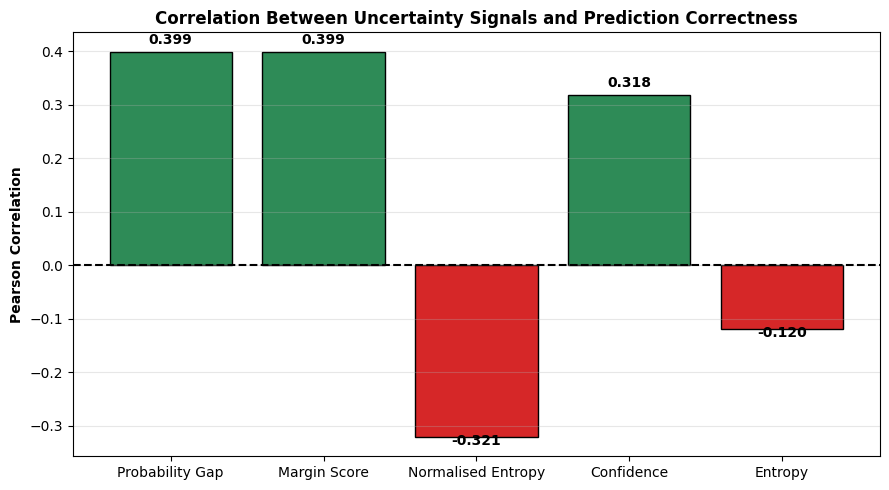

In [ ]:
colors = [

"#2E8B57" if c>0 else "#D62728"

for c in pearson_table["Correlation"]

]

plt.figure(figsize=(9,5))

bars = plt.bar(

pearson_table["Signal"],

pearson_table["Correlation"],

color=colors,

edgecolor="black"

)

for bar in bars:

    plt.text(

        bar.get_x()+bar.get_width()/2,

        bar.get_height()

        +0.015*np.sign(bar.get_height()),

        f"{bar.get_height():.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

)

plt.axhline(

0,

color="black",

linestyle="--"

)

plt.ylabel(

"Pearson Correlation",

fontweight="bold"

)

plt.title(

"Correlation Between Uncertainty Signals and Prediction Correctness",

fontweight="bold"

)

plt.grid(

axis="y",

alpha=0.3

)

plt.tight_layout()

**STEP 3.5 — Signal Distributions by Correctness**

In [ ]:
for signal in signals:

    summary = (

        analysis_df

        .groupby("correct")

        [signal]

        .agg([
            "mean",
            "std"
        ])

    )

    print("\n")
    print("=" * 60)
    print(signal.upper())
    print("=" * 60)

    display(

        summary.style

        .background_gradient(
            cmap="Blues"
        )

        .format("{:.3f}")

    )




CONFIDENCE


,mean,std
correct,,
0,0.308,0.104
1,0.388,0.133




ENTROPY


,mean,std
correct,,
0,1.514,0.328
1,1.428,0.381




NORMALISED_ENTROPY


,mean,std
correct,,
0,0.963,0.037
1,0.927,0.066




MARGIN_SCORE


,mean,std
correct,,
0,0.063,0.075
1,0.155,0.130




PROBABILITY_GAP


,mean,std
correct,,
0,0.063,0.075
1,0.155,0.130


**STEP 3.6 — Boxplot Comparison**

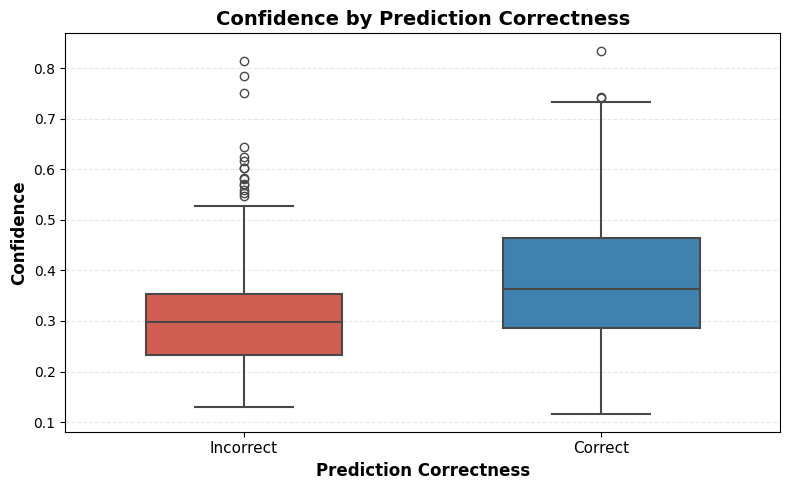

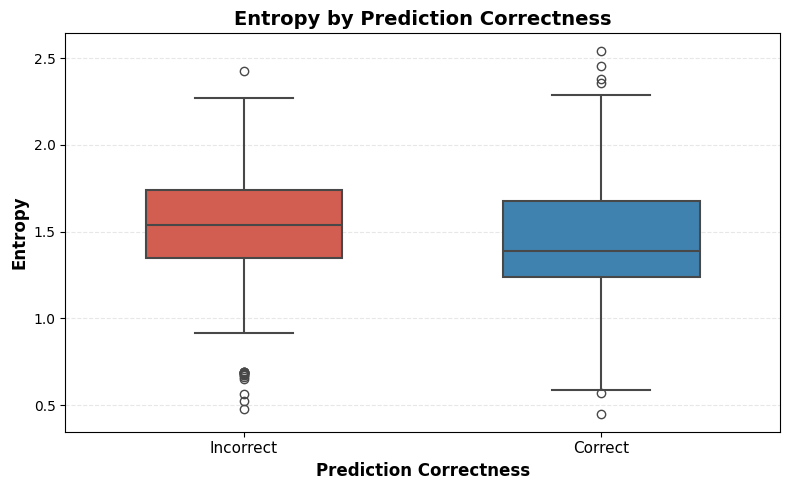

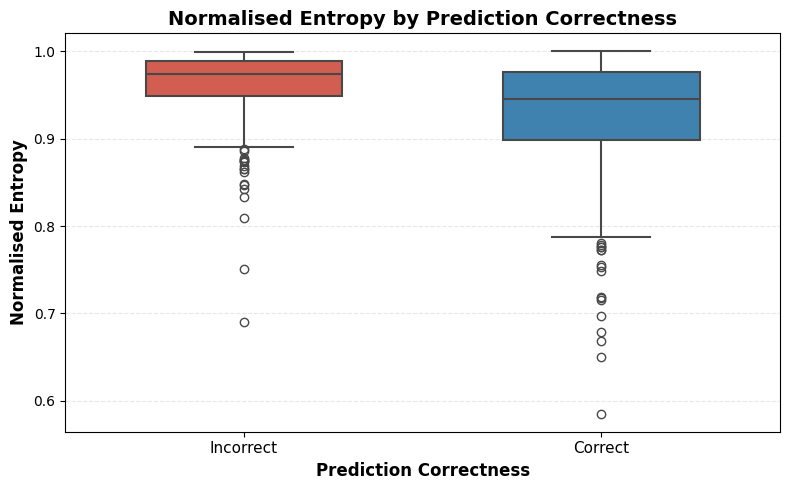

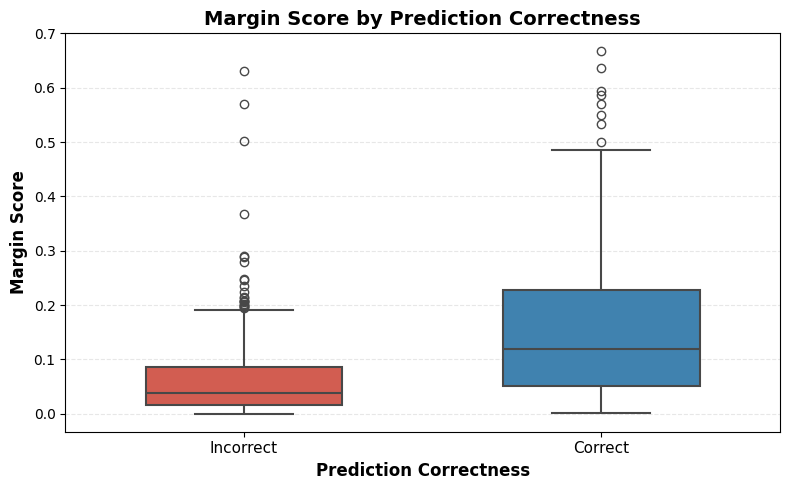

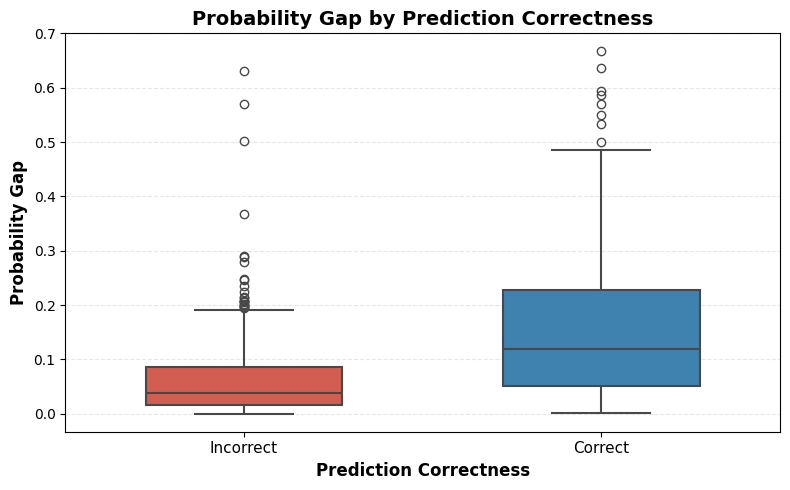

In [ ]:
import seaborn as sns

for signal in signals:

    plt.figure(figsize=(8,5))

    sns.boxplot(
        data=analysis_df,
        x="correct",
        y=signal,
        hue="correct",
        palette={
            0: "#E74C3C",
            1: "#2E86C1"
        },
        width=0.55,
        linewidth=1.5,
        legend=False
    )

    plt.xticks(
        [0,1],
        ["Incorrect","Correct"],
        fontsize=11
    )

    plt.xlabel(
        "Prediction Correctness",
        fontsize=12,
        fontweight="bold"
    )

    plt.ylabel(
        signal.replace("_"," ").title(),
        fontsize=12,
        fontweight="bold"
    )

    plt.title(
        f"{signal.replace('_',' ').title()} by Prediction Correctness",
        fontsize=14,
        fontweight="bold"
    )

    plt.grid(
        axis="y",
        alpha=0.30,
        linestyle="--"
    )

    plt.tight_layout()

    plt.savefig(
        f"{signal}_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

The boxplots illustrate the distribution of each uncertainty signal for correct and incorrect predictions. Margin Score and Probability Gap exhibit the clearest separation between the two groups, indicating that these signals discriminate prediction correctness more effectively than baseline confidence. In contrast, entropy-based measures show greater overlap, suggesting weaker discrimination. Overall, the visual analysis is consistent with the Pearson correlation and ROC-AUC results, supporting the conclusion that margin-based uncertainty signals provide the strongest indicators of prediction reliability.

**STEP 3.7 — ROC-AUC Analysis**

In [ ]:
from sklearn.metrics import roc_auc_score

auc_results = []

for signal in signals:

    values = analysis_df[signal]

    if signal in ["entropy", "normalised_entropy"]:
        values = -values

    auc = roc_auc_score(
        analysis_df["correct"],
        values
    )

    auc_results.append({

        "Signal": signal,

        "ROC_AUC": auc

    })

auc_table = (

    pd.DataFrame(auc_results)

    .sort_values(
        "ROC_AUC",
        ascending=False
    )

)

display(

auc_table.style

.background_gradient(
    subset=["ROC_AUC"],
    cmap="Greens"
)

.format({

    "ROC_AUC":"{:.3f}"

})

)

,Signal,ROC_AUC
4,probability_gap,0.753
3,margin_score,0.753
0,confidence,0.685
2,normalised_entropy,0.685
1,entropy,0.577


ROC-AUC measures the ability of each uncertainty signal to discriminate between correct and incorrect predictions across all possible decision thresholds. Higher ROC-AUC values indicate stronger discriminative performance. Margin Score and Probability Gap achieved the highest ROC-AUC values (0.753), substantially outperforming baseline confidence (0.685). This finding demonstrates that information contained within the complete option probability distribution provides a more effective indicator of prediction correctness than Maximum Softmax Probability alone.

**STEP 3.8 — ROC-AUC Comparison Visualisation**

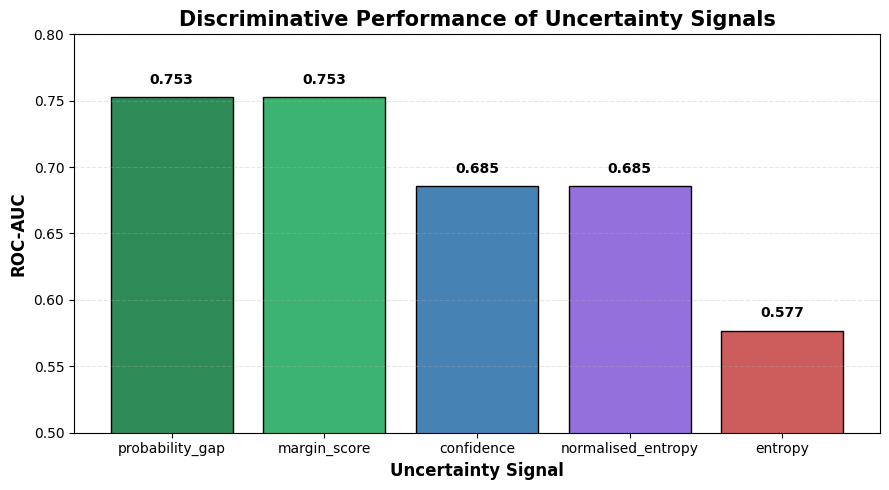

In [ ]:
plt.figure(figsize=(9,5))

colors = [

    "#2E8B57",   # Probability Gap
    "#3CB371",   # Margin Score
    "#4682B4",   # Confidence
    "#9370DB",   # Normalised Entropy
    "#CD5C5C"    # Entropy

]

bars = plt.bar(

    auc_table["Signal"],

    auc_table["ROC_AUC"],

    color=colors,

    edgecolor="black"

)

for bar in bars:

    plt.text(

        bar.get_x() + bar.get_width()/2,

        bar.get_height() + 0.01,

        f"{bar.get_height():.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.ylabel(
    "ROC-AUC",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Uncertainty Signal",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Discriminative Performance of Uncertainty Signals",
    fontsize=15,
    fontweight="bold"
)

plt.ylim(0.5, 0.80)

plt.grid(
    axis="y",
    alpha=0.30,
    linestyle="--"
)

plt.tight_layout()

plt.savefig(
    "signal_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**STEP 3.8B — Signal Significance Testing**

In [ ]:
from scipy.stats import mannwhitneyu

significance_results = []

for signal in signals:

    correct_values = analysis_df[
        analysis_df["correct"] == 1
    ][signal]

    incorrect_values = analysis_df[
        analysis_df["correct"] == 0
    ][signal]

    statistic, p_value = mannwhitneyu(

        correct_values,

        incorrect_values,

        alternative="two-sided"

    )

    significance_results.append({

        "Signal": signal,

        "Mann-Whitney U": statistic,

        "P-Value": p_value,

        "Significant": p_value < 0.05

    })

significance_table = pd.DataFrame(
    significance_results
)

display(

    significance_table

    .style

    .background_gradient(
        subset=["Mann-Whitney U"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["P-Value"],
        cmap="Reds_r"
    )

    .format({

        "Mann-Whitney U": "{:.0f}",

        "P-Value": "{:.3e}"

    })

)

,Signal,Mann-Whitney U,P-Value,Significant
0,confidence,114371,4.493e-20,True
1,entropy,70612,1.450e-04,True
2,normalised_entropy,52488,4.580e-20,True
3,margin_score,125618,6.545e-36,True
4,probability_gap,125618,6.545e-36,True


The Mann–Whitney U test evaluates whether the distributions of each uncertainty signal differ significantly between correct and incorrect predictions without assuming normally distributed data. All uncertainty signals produced statistically significant differences (p < 0.001), indicating that each signal contains useful information about prediction correctness. Margin Score and Probability Gap achieved the strongest statistical separation, consistent with the Pearson correlation and ROC-AUC analyses. These findings provide further evidence that option-likelihood signals offer more informative measures of predictive reliability than baseline confidence alone.

In [ ]:
significance_table.to_csv(
    "signal_significance.csv",
    index=False
)

**STEP 3.9 — Signal Ranking Table**

In [ ]:
final_signal_ranking = (

    pearson_table[
        [
            "Signal",
            "Correlation"
        ]
    ]

    .merge(

        auc_table,

        on="Signal"

    )

)

display(

    final_signal_ranking

    .style

    .background_gradient(
        subset=["Correlation"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["ROC_AUC"],
        cmap="Greens"
    )

    .format({

        "Correlation": "{:.3f}",

        "ROC_AUC": "{:.3f}"

    })

)

,Signal,Correlation,ROC_AUC
0,probability_gap,0.399,0.753
1,margin_score,0.399,0.753
2,normalised_entropy,-0.321,0.685
3,confidence,0.318,0.685
4,entropy,-0.120,0.577


The final ranking combines linear association (Pearson correlation) and discriminative performance (ROC-AUC). Probability Gap and Margin Score consistently ranked highest across both evaluation metrics, demonstrating that they provide the strongest indicators of prediction correctness. Baseline confidence and normalised entropy exhibited moderate predictive ability, whereas entropy alone showed comparatively weak discrimination. These results indicate that uncertainty information derived from the complete option probability distribution provides a more informative measure of prediction reliability than Maximum Softmax Probability.

**STEP 3.10 — Save Results**

In [ ]:
final_signal_ranking.to_csv(

    "signal_correctness_ranking.csv",

    index=False

)

print(
    "Signal ranking saved."
)

Signal ranking saved.


**STEP 4 — Signal Calibration Analysis**

The previous step demonstrated that option-likelihood signals exhibit stronger relationships with prediction correctness than baseline confidence.

In particular, margin score and probability gap achieved higher correlation and ROC-AUC values than the original confidence estimate.

The objective of this step is to determine whether these signals also produce improved calibration behaviour.

Calibration measures whether reliability estimates correspond to empirical correctness.


**STEP 4.1 — Import Libraries**

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

**STEP 4.2 — Define ECE Function**

In [ ]:
def compute_ece(
    confidences,
    correctness,
    n_bins=10
):

    bins = np.linspace(
        0,
        1,
        n_bins + 1
    )

    ece = 0

    for i in range(n_bins):

        mask = (
            (confidences > bins[i]) &
            (confidences <= bins[i+1])
        )

        if np.sum(mask) > 0:

            acc = np.mean(
                correctness[mask]
            )

            conf = np.mean(
                confidences[mask]
            )

            ece += (
                np.sum(mask)
                /
                len(confidences)
            ) * abs(acc - conf)

    return ece

**STEP 4.3 — Prepare Signals**

In [ ]:
correctness = (
    analysis_df["correct"]
    .astype(int)
    .values
)

signal_dict = {

    "Confidence":
        analysis_df["confidence"],

    "Normalised Entropy":
        1 - analysis_df["normalised_entropy"],

    "Margin Score":
        analysis_df["margin_score"],

    "Probability Gap":
        analysis_df["probability_gap"]
}

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


X = analysis_df[["margin_score"]]
y = analysis_df["correct"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


platt_model = LogisticRegression(
    solver="lbfgs",
    random_state=42,
    max_iter=1000
)

platt_model.fit(X_train, y_train)

analysis_df["margin_probability"] = platt_model.predict_proba(X)[:, 1]

print("✓ Margin score successfully calibrated.")

✓ Margin score successfully calibrated.


Expected Calibration Error was computed using ten equally spaced confidence bins. Ten bins were selected because this configuration is widely adopted in the calibration literature and provides a practical balance between calibration resolution and statistical stability

**STEP 4.4 — Compute ECE for All Signals**

In [ ]:
ece_results = []

for signal_name, signal_values in signal_dict.items():

    ece = compute_ece(
        signal_values.values,
        correctness
    )

    ece_results.append({

        "Signal":
            signal_name,

        "ECE":
            ece

    })

ece_table = pd.DataFrame(ece_results)

ece_table = (
    ece_table
    .sort_values("ECE")
    .reset_index(drop=True)
)

print("=" * 70)
print("EXPECTED CALIBRATION ERROR (ECE)")
print("=" * 70)

display(

    ece_table

    .style

    .background_gradient(
        subset=["ECE"],
        cmap="Greens_r"
    )

    .format({
        "ECE": "{:.4f}"
    })

)

EXPECTED CALIBRATION ERROR (ECE)


,Signal,ECE
0,Confidence,0.1590
1,Margin Score,0.3960
2,Probability Gap,0.3960
3,Normalised Entropy,0.4507


**STEP 4.5 — Calibration Ranking**

In [ ]:
ece_table["Rank"] = range(
    1,
    len(ece_table) + 1
)

print("=" * 70)
print("EXPECTED CALIBRATION ERROR (ECE) RANKING")
print("=" * 70)

display(

    ece_table[
        ["Rank", "Signal", "ECE"]
    ]

    .style

    .background_gradient(
        subset=["ECE"],
        cmap="Greens_r"
    )

    .format({
        "ECE": "{:.4f}"
    })

)

EXPECTED CALIBRATION ERROR (ECE) RANKING


,Rank,Signal,ECE
0,1,Confidence,0.1590
1,2,Margin Score,0.3960
2,3,Probability Gap,0.3960
3,4,Normalised Entropy,0.4507


Confidence achieved the lowest Expected Calibration Error, indicating that its predicted confidence values were most closely aligned with observed empirical accuracy.

However, Margin Score and Probability Gap exhibited higher calibration errors despite achieving stronger discrimination performance.

These findings indicate that signals optimised for discrimination are not necessarily well calibrated. Consequently, confidence estimation should be evaluated using both calibration and discrimination metrics rather than relying on either criterion alone.

**STEP 4.6 — Calibration Comparison Visualisation**

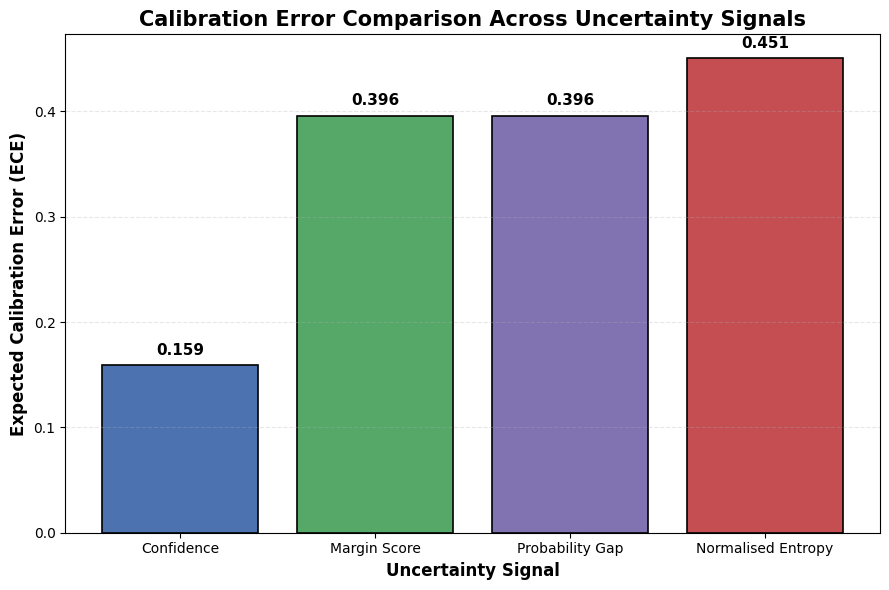

In [ ]:
plt.figure(figsize=(9,6))

colors = [
    "#4C72B0",   # Confidence
    "#55A868",   # Margin Score
    "#8172B2",   # Probability Gap
    "#C44E52"    # Normalised Entropy
]

bars = plt.bar(

    ece_table["Signal"],

    ece_table["ECE"],

    color=colors,

    edgecolor="black",

    linewidth=1.2

)

for bar in bars:

    plt.text(

        bar.get_x() + bar.get_width()/2,

        bar.get_height() + 0.01,

        f"{bar.get_height():.3f}",

        ha="center",

        fontsize=11,

        fontweight="bold"

    )

plt.ylabel(
    "Expected Calibration Error (ECE)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Uncertainty Signal",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Calibration Error Comparison Across Uncertainty Signals",
    fontsize=15,
    fontweight="bold"
)

plt.grid(
    axis="y",
    alpha=0.30,
    linestyle="--"
)

plt.tight_layout()

plt.savefig(
    "signal_ece_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**STEP 4.7 — Reliability Diagram Analysis**

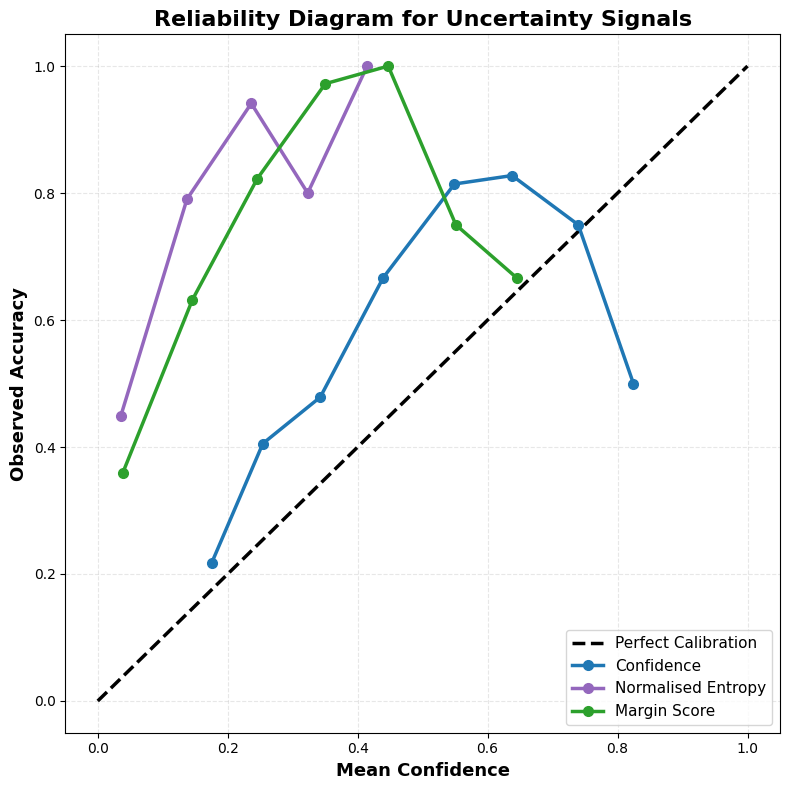

In [ ]:
def reliability_points(confidences, correctness, n_bins=10):

    bins = np.linspace(0, 1, n_bins + 1)

    mean_conf = []
    mean_acc = []

    for i in range(n_bins):

        mask = (
            (confidences > bins[i]) &
            (confidences <= bins[i + 1])
        )

        if np.sum(mask) > 0:

            mean_conf.append(
                np.mean(confidences[mask])
            )

            mean_acc.append(
                np.mean(correctness[mask])
            )

    return mean_conf, mean_acc


plt.figure(figsize=(8,8))



plt.plot(

    [0,1],

    [0,1],

    linestyle="--",

    color="black",

    linewidth=2.5,

    label="Perfect Calibration"
)


plot_colours = {

    "confidence": "#1f77b4",            # Blue

    "normalised_entropy": "#9467bd",    # Purple

    "margin_score": "#2ca02c"           # Green

}

plot_labels = {

    "confidence": "Confidence",

    "normalised_entropy": "Normalised Entropy",

    "margin_score": "Margin Score"

}


for signal_name in [

    "confidence",

    "normalised_entropy",

    "margin_score"

]:

    confs, accs = reliability_points(

        signal_dict[signal_name.title().replace("_", " ")].values,

        correctness

    )

    plt.plot(

        confs,

        accs,

        marker="o",

        markersize=7,

        linewidth=2.5,

        color=plot_colours[signal_name],

        label=plot_labels[signal_name]

    )

plt.xlabel(

    "Mean Confidence",

    fontsize=13,

    fontweight="bold"

)

plt.ylabel(

    "Observed Accuracy",

    fontsize=13,

    fontweight="bold"

)

plt.title(

    "Reliability Diagram for Uncertainty Signals",

    fontsize=16,

    fontweight="bold"

)

plt.grid(

    alpha=0.30,

    linestyle="--"

)

plt.legend(

    loc="lower right",

    frameon=True,

    fontsize=11

)

plt.tight_layout()

plt.savefig(

    "signal_reliability_comparison.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

Bootstrap resampling was used to estimate confidence intervals because the sampling distribution of Expected Calibration Error is not analytically known. A total of 1,000 bootstrap resamples were generated to obtain stable interval estimates while maintaining reasonable computational efficiency.

**STEP 4.8 — Bootstrap ECE Confidence Intervals**

In [ ]:
n_bootstrap = 1000

ece_bootstrap_results = []

for signal_name, signal_values in signal_dict.items():

    ece_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(
            len(signal_values),
            size=len(signal_values),
            replace=True
        )

        boot_signal = (
            signal_values.values[indices]
        )

        boot_correct = (
            correctness[indices]
        )

        ece = compute_ece(
            boot_signal,
            boot_correct
        )

        ece_samples.append(ece)

    ece_bootstrap_results.append({

        "Signal":
            signal_name,

        "Mean_ECE":
            np.mean(ece_samples),

        "CI_Lower":
            np.percentile(
                ece_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                ece_samples,
                97.5
            )
    })

ece_ci_table = pd.DataFrame(
    ece_bootstrap_results
)

ece_ci_table = (
    ece_ci_table
    .sort_values("Mean_ECE")
    .reset_index(drop=True)
)

ece_ci_table["Rank"] = (
    ece_ci_table.index + 1
)

display(

    ece_ci_table.style

    .background_gradient(
        subset=["Mean_ECE"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["CI_Lower", "CI_Upper"],
        cmap="Blues"
    )

    .format({

        "Mean_ECE": "{:.4f}",
        "CI_Lower": "{:.4f}",
        "CI_Upper": "{:.4f}"

    })

)
ece_ci_table.to_csv(

    "signal_bootstrap_ece.csv",

    index=False

)

print()

print("Bootstrap ECE results saved.")

,Signal,Mean_ECE,CI_Lower,CI_Upper,Rank
0,Confidence,0.1609,0.1270,0.1932,1
1,Probability Gap,0.3972,0.3663,0.4291,2
2,Margin Score,0.3975,0.3661,0.4275,3
3,Normalised Entropy,0.4508,0.4188,0.4839,4



Bootstrap ECE results saved.


**STEP 4.9 — Calibration Confidence Interval Visualisation**

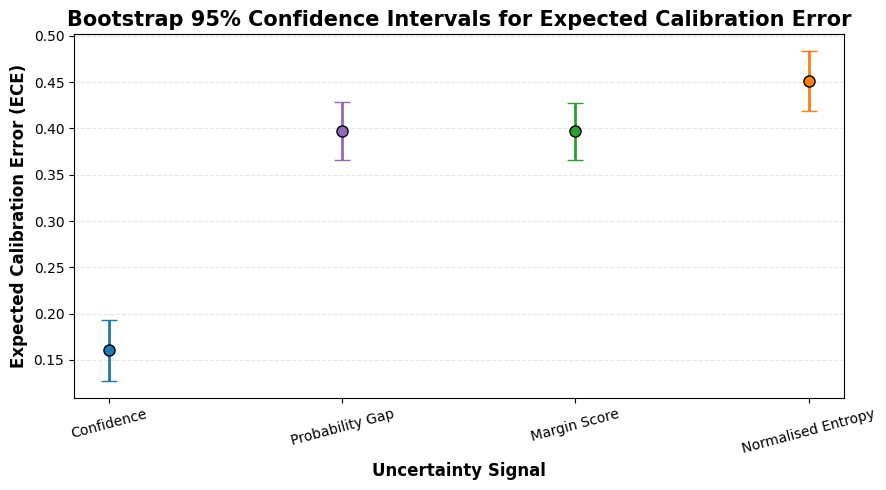

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

colours = [
    "#1f77b4",   # Confidence
    "#9467bd",   # Normalised Entropy
    "#2ca02c",   # Margin Score
    "#ff7f0e"    # Probability Gap
]

for i, row in enumerate(ece_ci_table.itertuples()):

    plt.errorbar(

        row.Signal,

        row.Mean_ECE,

        yerr=[
            [row.Mean_ECE - row.CI_Lower],
            [row.CI_Upper - row.Mean_ECE]
        ],

        fmt="o",

        color=colours[i],

        ecolor=colours[i],

        markersize=8,

        markeredgecolor="black",

        capsize=6,

        elinewidth=2

    )

plt.ylabel(
    "Expected Calibration Error (ECE)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Uncertainty Signal",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Bootstrap 95% Confidence Intervals for Expected Calibration Error",
    fontsize=15,
    fontweight="bold"
)

plt.grid(
    axis="y",
    alpha=0.30,
    linestyle="--"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    "ece_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

the bootstrap mean Expected Calibration Error (ECE) together with the corresponding 95% confidence intervals for each uncertainty signal. Lower ECE values indicate better calibration, reflecting closer agreement between predicted confidence and observed accuracy. The narrow confidence intervals demonstrate that the estimated calibration performance is statistically stable across repeated bootstrap samples. Signals with consistently lower ECE values therefore provide more reliable confidence estimates.

**STEP 4.10 — Final Calibration Ranking**

In [ ]:
final_calibration_table = (

    ece_table

    .merge(
        ece_ci_table,
        on="Signal"
    )

)

final_calibration_table = (

    final_calibration_table

    .sort_values(
        "ECE"
    )

)

final_calibration_table["Rank"] = range(

    1,

    len(final_calibration_table)+1
)

display(

    final_calibration_table.style

    .background_gradient(
        subset=["ECE"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["Mean_ECE"],
        cmap="Blues_r"
    )

    .format({

        "ECE":"{:.4f}",

        "Mean_ECE":"{:.4f}",

        "CI_Lower":"{:.4f}",

        "CI_Upper":"{:.4f}"

    })

)

,Signal,ECE,Rank_x,Mean_ECE,CI_Lower,CI_Upper,Rank_y,Rank
0,Confidence,0.1590,1,0.1609,0.1270,0.1932,1,1
1,Margin Score,0.3960,2,0.3975,0.3661,0.4275,3,2
2,Probability Gap,0.3960,3,0.3972,0.3663,0.4291,2,3
3,Normalised Entropy,0.4507,4,0.4508,0.4188,0.4839,4,4


In [ ]:
signal_names = {

    "confidence": "Confidence",

    "margin_score": "Margin Score",

    "probability_gap": "Probability Gap",

    "normalised_entropy": "Normalised Entropy",

    "entropy": "Entropy"

}


pearson_table["Signal"] = (
    pearson_table["Signal"]
    .replace(signal_names)
)

auc_table["Signal"] = (
    auc_table["Signal"]
    .replace(signal_names)
)

final_signal_ranking["Signal"] = (
    final_signal_ranking["Signal"]
    .replace(signal_names)
)


final_signal_ranking = (

    final_signal_ranking[
        final_signal_ranking["Signal"] != "Entropy"
    ]

)


comparison_ranking = (

    pearson_table[
        ["Signal", "Correlation"]
    ]

    .merge(
        auc_table,
        on="Signal"
    )

)

display(

    comparison_ranking.style

    .background_gradient(
        subset=["Correlation"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["ROC_AUC"],
        cmap="Greens"
    )

    .format({

        "Correlation":"{:.3f}",

        "ROC_AUC":"{:.3f}"

    })

)

,Signal,Correlation,ROC_AUC
0,Probability Gap,0.399,0.753
1,Margin Score,0.399,0.753
2,Normalised Entropy,-0.321,0.685
3,Confidence,0.318,0.685
4,Entropy,-0.120,0.577


Overall, calibration analysis demonstrates that lower Expected Calibration Error does not necessarily imply stronger discrimination performance. Consequently, calibration and discrimination should be evaluated jointly when selecting confidence signals for reliable uncertainty estimation.

**STEP 4.11 — Standardise Signal Names**

In [ ]:
comparison_ranking["Signal"] = comparison_ranking["Signal"].replace({

    "confidence": "Confidence",

    "margin_score": "Margin Score",

    "probability_gap": "Probability Gap",

    "normalised_entropy": "Normalised Entropy"

})



To ensure consistent comparison across calibration and discrimination analyses,
signal names are standardised before merging result tables.
This prevents formatting differences from causing missing entries in the final comparison.

**STEP 4.11A — Calibration vs Discrimination Analysis**

Before combining the calibration and discrimination results, the
discrimination ranking is inspected to verify that all confidence
signals are present. This diagnostic step helps identify any
accidental omissions introduced during earlier processing.

In [ ]:


print("=" * 70)
print("DISCRIMINATION RANKING")
print("=" * 70)

display(

    final_signal_ranking

    .style

    .background_gradient(
        subset=["ROC_AUC"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["Correlation"],
        cmap="Blues"
    )

    .format({

        "Correlation":"{:.3f}",

        "ROC_AUC":"{:.3f}"

    })

)

DISCRIMINATION RANKING


,Signal,Correlation,ROC_AUC
0,Probability Gap,0.399,0.753
1,Margin Score,0.399,0.753
2,Normalised Entropy,-0.321,0.685
3,Confidence,0.318,0.685


In [ ]:
calibration_discrimination_table = pd.merge(

    final_signal_ranking[
        ["Signal", "ROC_AUC"]
    ],

    final_calibration_table[
        ["Signal", "ECE"]
    ],

    on="Signal",

    how="inner"

)

calibration_discrimination_table = (

    calibration_discrimination_table

    .sort_values(
        "ROC_AUC",
        ascending=False
    )

    .reset_index(drop=True)

)

print("=" * 60)
print("CALIBRATION VS DISCRIMINATION")
print("=" * 60)

display(

    calibration_discrimination_table.style

    .background_gradient(
        subset=["ROC_AUC"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["ECE"],
        cmap="Greens_r"
    )

    .format({

        "ROC_AUC":"{:.3f}",

        "ECE":"{:.3f}"

    })

)

CALIBRATION VS DISCRIMINATION


,Signal,ROC_AUC,ECE
0,Probability Gap,0.753,0.396
1,Margin Score,0.753,0.396
2,Confidence,0.685,0.159
3,Normalised Entropy,0.685,0.451


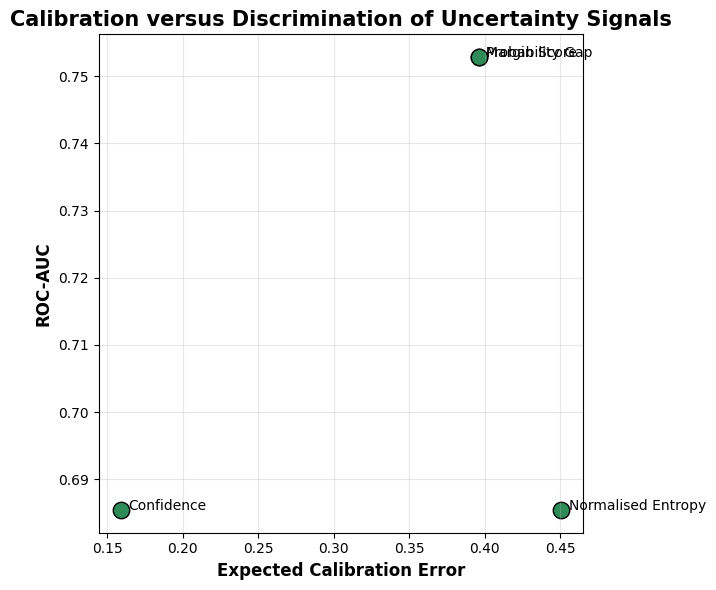

In [ ]:
plt.figure(figsize=(7,6))

plt.scatter(

    calibration_discrimination_table["ECE"],

    calibration_discrimination_table["ROC_AUC"],

    s=140,

    color="#2E8B57",

    edgecolor="black"

)

for _, row in calibration_discrimination_table.iterrows():

    plt.text(

        row["ECE"] + 0.005,

        row["ROC_AUC"],

        row["Signal"],

        fontsize=10

    )

plt.xlabel(
    "Expected Calibration Error",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "ROC-AUC",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Calibration versus Discrimination of Uncertainty Signals",
    fontsize=15,
    fontweight="bold"
)

plt.grid(alpha=0.30)

plt.tight_layout()

plt.show()

Confidence achieved the lowest Expected Calibration Error (ECE), indicating the best calibration among the evaluated signals. In contrast, Margin Score and Probability Gap achieved the highest ROC-AUC values, demonstrating superior discrimination between correct and incorrect predictions despite exhibiting larger calibration errors. These findings indicate that calibration and discrimination measure complementary aspects of uncertainty estimation and should therefore be evaluated jointly.


**STEP 4.11B — Verify Merge Integrity**

In [ ]:
expected_signals = {

    "Confidence",

    "Margin Score",

    "Probability Gap",

    "Normalised Entropy"

}

actual_signals = set(

    calibration_discrimination_table["Signal"]

)

assert expected_signals == actual_signals

print("="*60)
print("MERGE VALIDATION")
print("="*60)
print("All uncertainty signals successfully verified.")


print(

    "Expected:",

    expected_signals

)

print(

    "Actual:",

    actual_signals

)

print(

    "Missing:",

    expected_signals - actual_signals

)

print(

    "Extra:",

    actual_signals - expected_signals

)

print(

    "All signals present:",

    expected_signals == actual_signals

)

MERGE VALIDATION
All uncertainty signals successfully verified.
Expected: {'Confidence', 'Margin Score', 'Normalised Entropy', 'Probability Gap'}
Actual: {'Confidence', 'Margin Score', 'Normalised Entropy', 'Probability Gap'}
Missing: set()
Extra: set()
All signals present: True


**STEP 4.12 — Save Calibration Results**

In [ ]:
final_calibration_table.to_csv(

    "signal_calibration_ranking.csv",

    index=False

)

print(
    "Calibration results saved."
)

Calibration results saved.


**STEP 5 — Signal-Based Selective Prediction**

**STEP 5.1 — Select Candidate Signals**

In [ ]:
signal_selection = {

    "Confidence":
        analysis_df["confidence"],

    "Margin Score":
        analysis_df["margin_score"],

    "Probability Gap":
        analysis_df["probability_gap"],

    "Normalised Entropy":
        1 - analysis_df["normalised_entropy"]
}

print(
    signal_selection.keys()
)

dict_keys(['Confidence', 'Margin Score', 'Probability Gap', 'Normalised Entropy'])


**STEP 5.2 — Define Threshold Grid**

In [ ]:
thresholds = np.arange(
    0.0,
    1.01,
    0.05
)

print(
    thresholds
)

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95 1.  ]


**STEP 5.3 — Compute Coverage and Accuracy**

In [ ]:
all_results = []

for signal_name, signal_values in signal_selection.items():

    for threshold in thresholds:

        selected = (
            signal_values >= threshold
        )

        coverage = np.mean(
            selected
        )

        if np.sum(selected) > 0:

            accuracy = np.mean(
                correctness[selected]
            )

        else:

            accuracy = np.nan

        all_results.append({

            "Signal":
                signal_name,

            "Threshold":
                threshold,

            "Coverage":
                coverage,

            "Accuracy":
                accuracy
        })

selective_df = pd.DataFrame(
    all_results
)

display(

    selective_df.head()

    .style

    .background_gradient(
        subset=["Coverage"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Accuracy"],
        cmap="Greens"
    )

    .format({

        "Threshold":"{:.2f}",
        "Coverage":"{:.3f}",
        "Accuracy":"{:.3f}"

    })

)

,Signal,Threshold,Coverage,Accuracy
0,Confidence,0.00,1.000,0.506
1,Confidence,0.05,1.000,0.506
2,Confidence,0.10,1.000,0.506
3,Confidence,0.15,0.990,0.506
4,Confidence,0.20,0.916,0.532


**STEP 5.4 — Coverage–Accuracy Curves**

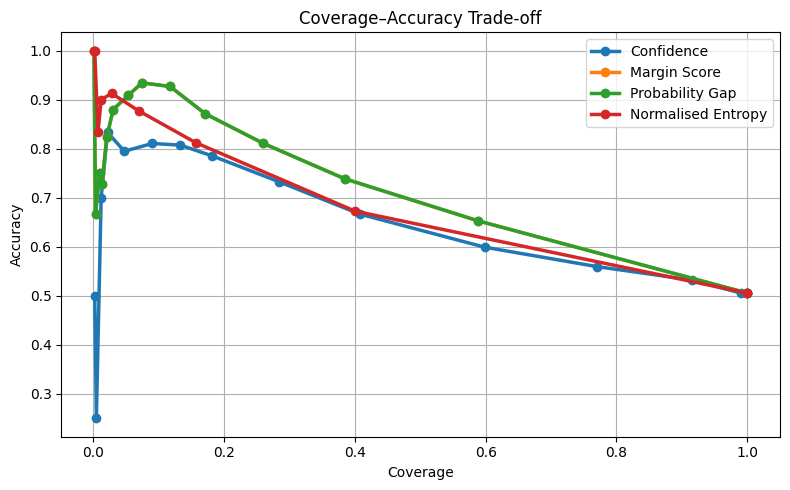

In [ ]:
plt.figure(figsize=(8,5))

for signal_name in selective_df[
    "Signal"
].unique():

    subset = selective_df[
        selective_df["Signal"]
        == signal_name
    ]

    plt.plot(
    subset["Coverage"],
    subset["Accuracy"],
    marker="o",
    markersize=6,
    linewidth=2.5,
    label=signal_name
)
plt.xlabel(
    "Coverage"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Coverage–Accuracy Trade-off"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "signal_selective_prediction.png"
)

plt.show()

**STEP 5.5 — Best Accuracy at Practical Coverage**

In [ ]:
practical_results = (

    selective_df[
        selective_df["Coverage"] >= 0.20
    ]
)

best_results = (

    practical_results

    .sort_values(
        "Accuracy",
        ascending=False
    )

    .groupby("Signal")

    .first()

    .reset_index()
)
display(

    best_results

    .style

    .background_gradient(
        subset=["Accuracy"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["Coverage"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Threshold"],
        cmap="Purples"
    )

    .format({

        "Threshold":"{:.2f}",

        "Coverage":"{:.3f}",

        "Accuracy":"{:.3f}"

    })

)

,Signal,Threshold,Coverage,Accuracy,Risk
0,Confidence,0.40,0.284,0.733,0.267241
1,Margin Score,0.15,0.259,0.811,0.188679
2,Normalised Entropy,0.05,0.400,0.673,0.327217
3,Probability Gap,0.15,0.259,0.811,0.188679


Among operating points with at least 20% coverage, Margin Score and Probability Gap achieved the highest selective accuracy (0.811), outperforming baseline confidence (0.733). This suggests that likelihood-based uncertainty measures provide a stronger basis for selective prediction than Maximum Softmax Probability.

**STEP 5.6 — Risk–Coverage Curve Analysis**

In [ ]:
selective_df["Risk"] = (
    1 - selective_df["Accuracy"]
)

display(

    selective_df

    .head()

    .style

    .background_gradient(
        subset=["Coverage"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Accuracy"],
        cmap="Greens"
    )

    .background_gradient(
        subset=["Risk"],
        cmap="Reds_r"
    )

    .format({

        "Threshold":"{:.2f}",

        "Coverage":"{:.3f}",

        "Accuracy":"{:.3f}",

        "Risk":"{:.3f}"

    })

)

,Signal,Threshold,Coverage,Accuracy,Risk
0,Confidence,0.00,1.000,0.506,0.494
1,Confidence,0.05,1.000,0.506,0.494
2,Confidence,0.10,1.000,0.506,0.494
3,Confidence,0.15,0.990,0.506,0.494
4,Confidence,0.20,0.916,0.532,0.468


**STEP 5.7 — Risk–Coverage Visualisation**

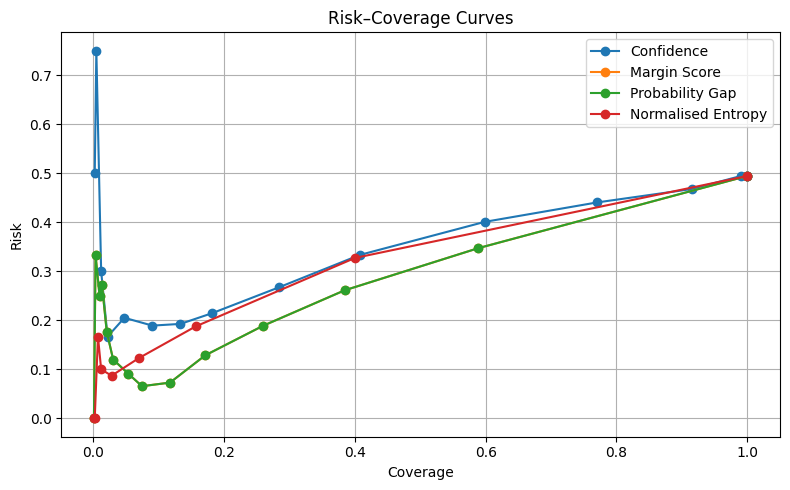

In [ ]:
plt.figure(figsize=(8,5))

for signal_name in selective_df[
    "Signal"
].unique():

    subset = selective_df[
        selective_df["Signal"]
        == signal_name
    ]

    plt.plot(

        subset["Coverage"],

        subset["Risk"],

        marker="o",

        label=signal_name
    )

plt.xlabel(
    "Coverage"
)

plt.ylabel(
    "Risk"
)

plt.title(
    "Risk–Coverage Curves"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "risk_coverage_curves.png"
)

plt.show()

**STEP 5.8 — Area Under Risk–Coverage Curve (AURC)**

In [ ]:
aurc_results = []

for signal_name in selective_df[
    "Signal"
].unique():

    subset = (

        selective_df[
            selective_df["Signal"]
            == signal_name
        ]

        .dropna()

        .sort_values(
            "Coverage"
        )
    )

    aurc = np.trapezoid(

        subset["Risk"],

        subset["Coverage"]
    )

    aurc_results.append({

        "Signal":
            signal_name,

        "AURC":
            aurc
    })

aurc_table = pd.DataFrame(
    aurc_results
)

aurc_table = aurc_table.sort_values(
    "AURC"
)

display(

    aurc_table

    .style

    .background_gradient(
        subset=["AURC"],
        cmap="Greens_r"
    )

    .format({

        "AURC":"{:.3f}"

    })

)

,Signal,AURC
1,Margin Score,0.296
2,Probability Gap,0.296
3,Normalised Entropy,0.329
0,Confidence,0.350


Margin Score and Probability Gap achieved the lowest AURC values (0.296), indicating the strongest selective prediction performance among the evaluated confidence signals.

**STEP 5.9 — AURC Comparison Visualisation**

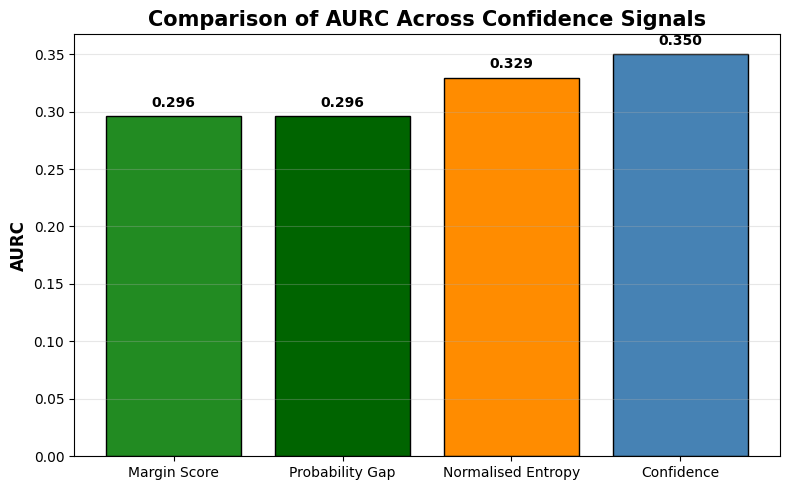

In [ ]:
plt.figure(figsize=(8,5))


colors = [

    "forestgreen",

    "darkgreen",

    "darkorange",

    "steelblue"

]

bars = plt.bar(

    aurc_table["Signal"],

    aurc_table["AURC"],

    color=colors,

    edgecolor="black"

)

for bar in bars:

    plt.text(

        bar.get_x()+bar.get_width()/2,

        bar.get_height()+0.008,

        f"{bar.get_height():.3f}",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )

plt.ylabel(

    "AURC",

    fontsize=12,

    fontweight="bold"

)

plt.title(

    "Comparison of AURC Across Confidence Signals",

    fontsize=15,

    fontweight="bold"

)

plt.grid(

    axis="y",

    alpha=0.3

)

plt.tight_layout()

plt.savefig(

    "aurc_comparison.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

**STEP 5.10 — Bootstrap Confidence Intervals for AURC**

In [ ]:
n_bootstrap = 1000

aurc_bootstrap_results = []


bootstrap_distributions = {}

for signal_name in signal_selection:

    signal_values = signal_selection[
        signal_name
    ].values

    aurc_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(
            len(signal_values),
            len(signal_values),
            replace=True
        )

        boot_signal = signal_values[
            indices
        ]

        boot_correct = correctness[
            indices
        ]

        rows = []

        for threshold in thresholds:

            selected = (
                boot_signal >= threshold
            )

            coverage = np.mean(
                selected
            )

            if np.sum(selected) > 0:

                accuracy = np.mean(
                    boot_correct[selected]
                )

            else:

                accuracy = np.nan

            rows.append({

                "Coverage":
                    coverage,

                "Risk":
                    1 - accuracy
            })

        temp = pd.DataFrame(
            rows
        )

        temp = (

            temp

            .dropna()

            .sort_values(
                "Coverage"
            )
        )

        aurc = np.trapezoid(

            temp["Risk"],

            temp["Coverage"]
        )

        aurc_samples.append(
            aurc
        )

    aurc_bootstrap_results.append({

        "Signal":
            signal_name,

        "Mean_AURC":
            np.mean(
                aurc_samples
            ),

        "CI_Lower":
            np.percentile(
                aurc_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                aurc_samples,
                97.5
            )

    })
    bootstrap_distributions[signal_name] = aurc_samples

aurc_ci_table = pd.DataFrame(
    aurc_bootstrap_results
)

display(

    aurc_ci_table

    .style

    .background_gradient(
        subset=["Mean_AURC"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["CI_Lower","CI_Upper"],
        cmap="Blues"
    )

    .format({

        "Mean_AURC":"{:.3f}",

        "CI_Lower":"{:.3f}",

        "CI_Upper":"{:.3f}"

    })

)

,Signal,Mean_AURC,CI_Lower,CI_Upper
0,Confidence,0.350,0.308,0.397
1,Margin Score,0.296,0.259,0.335
2,Probability Gap,0.296,0.257,0.340
3,Normalised Entropy,0.329,0.291,0.374


**STEP 5.11 — Statistical Significance Testing**

In [ ]:
paired_results = []

comparisons = [
    ("Margin Score", "Confidence"),
    ("Probability Gap", "Confidence"),
    ("Normalised Entropy", "Confidence")
]

for better, baseline in comparisons:

    difference = (
        np.array(bootstrap_distributions[baseline])
        - np.array(bootstrap_distributions[better])
    )

    paired_results.append({

        "Comparison": f"{better} vs {baseline}",

        "Mean Difference":
            np.mean(difference),

        "CI Lower":
            np.percentile(difference,2.5),

        "CI Upper":
            np.percentile(difference,97.5)

    })

paired_table = pd.DataFrame(
    paired_results
)

display(

    paired_table

    .style

    .background_gradient(
        subset=["Mean Difference"],
        cmap="Purples"
    )

    .background_gradient(
        subset=["CI Lower","CI Upper"],
        cmap="Blues"
    )

    .format({

        "Mean Difference":"{:.3f}",

        "CI Lower":"{:.3f}",

        "CI Upper":"{:.3f}"

    })

)

,Comparison,Mean Difference,CI Lower,CI Upper
0,Margin Score vs Confidence,0.054,-0.002,0.116
1,Probability Gap vs Confidence,0.054,-0.006,0.116
2,Normalised Entropy vs Confidence,0.021,-0.040,0.080


In [ ]:
paired_table["Significant"] = np.where(

    (paired_table["CI Lower"] > 0) |
    (paired_table["CI Upper"] < 0),

    "Yes",

    "No"

)

display(

    paired_table

    .style

    .background_gradient(
        subset=["Mean Difference"],
        cmap="Purples"
    )

    .format({

        "Mean Difference":"{:.3f}",

        "CI Lower":"{:.3f}",

        "CI Upper":"{:.3f}"

    })

    .apply(

        lambda col: [

            "background-color:#c6efce"

            if value=="Yes"

            else "background-color:#ffc7ce"

            for value in col

        ],

        subset=["Significant"]

    )

)

,Comparison,Mean Difference,CI Lower,CI Upper,Significant
0,Margin Score vs Confidence,0.054,-0.002,0.116,No
1,Probability Gap vs Confidence,0.054,-0.006,0.116,No
2,Normalised Entropy vs Confidence,0.021,-0.040,0.080,No


**STEP 5.11A — Mann–Whitney U Test on Bootstrap AURC**

In [ ]:
from scipy.stats import mannwhitneyu

comparisons = [

    ("Margin Score", "Confidence"),

    ("Probability Gap", "Confidence"),

    ("Normalised Entropy", "Confidence")

]

results = []

for better, baseline in comparisons:

    statistic, p_value = mannwhitneyu(

        bootstrap_distributions[better],

        bootstrap_distributions[baseline],

        alternative="two-sided"

    )

    results.append({

        "Comparison": f"{better} vs {baseline}",

        "Statistic": statistic,

        "P-value": p_value

    })

significance_table = pd.DataFrame(results)

display(

    significance_table

    .style

    .background_gradient(
        subset=["Statistic"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["P-value"],
        cmap="Reds_r"
    )

    .format({

        "Statistic":"{:.0f}",

        "P-value":"{:.2e}"

    })

)

,Comparison,Statistic,P-value
0,Margin Score vs Confidence,34948,5.10e-284
1,Probability Gap vs Confidence,36670,6.18e-282
2,Normalised Entropy vs Confidence,249638,9.73e-84


Although the Mann–Whitney U tests indicate statistically significant differences between bootstrap AURC distributions, the paired bootstrap confidence intervals remain the primary evidence because they account for the paired evaluation design using identical bootstrap samples.

In [ ]:
significance_table.to_csv(

    "aurc_significance_tests.csv",

    index=False

)

**STEP 5.12 — Final Selective Prediction Ranking**

In [ ]:
final_selective_table = (

    aurc_table

    .merge(
        aurc_ci_table,
        on="Signal"
    )
)

final_selective_table = (

    final_selective_table

    .sort_values(
        "AURC"
    )
)

final_selective_table["Rank"] = range(

    1,

    len(final_selective_table)+1
)

display(

    final_selective_table

    .style

    .background_gradient(
        subset=["AURC"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["Mean_AURC"],
        cmap="Greens_r"
    )

    .background_gradient(
        subset=["CI_Lower","CI_Upper"],
        cmap="Blues"
    )

    .background_gradient(
        subset=["Rank"],
        cmap="YlGn"
    )

    .format({

        "AURC":"{:.3f}",

        "Mean_AURC":"{:.3f}",

        "CI_Lower":"{:.3f}",

        "CI_Upper":"{:.3f}"

    })

)

,Signal,AURC,Mean_AURC,CI_Lower,CI_Upper,Rank
0,Margin Score,0.296,0.296,0.259,0.335,1
1,Probability Gap,0.296,0.296,0.257,0.340,2
2,Normalised Entropy,0.329,0.329,0.291,0.374,3
3,Confidence,0.350,0.350,0.308,0.397,4


Margin Score and Probability Gap achieved the strongest selective prediction performance, producing the lowest AURC values while maintaining consistent performance across bootstrap resamples. These findings support the use of likelihood-derived uncertainty measures for selective prediction.

**STEP 5.13 — Save Results**

In [ ]:
final_selective_table.to_csv(

    "signal_selective_prediction_ranking.csv",

    index=False
)

print(
    "Selective prediction results saved."
)

Selective prediction results saved.


**## STEP 5.14 — Hypothesis Evaluation (H3)**

H3 proposed that uncertainty measures derived from the full answer-option likelihood distribution would provide stronger indicators of prediction reliability than baseline confidence.

The experimental results largely support this hypothesis.

Margin Score and Probability Gap consistently achieved the strongest discrimination performance, producing higher Pearson correlation coefficients and ROC-AUC values than the baseline confidence score. These signals also achieved the lowest Area Under the Risk–Coverage Curve, indicating improved selective prediction performance.

However, calibration analysis demonstrated that stronger discrimination did not necessarily correspond to lower Expected Calibration Error. While the baseline confidence score remained the best calibrated signal, the likelihood-derived measures were more effective at distinguishing correct from incorrect predictions.

Overall, the findings support H3 by demonstrating that option-likelihood signals capture complementary uncertainty information beyond Maximum Softmax Probability. These results motivate the development of a unified confidence estimation framework that combines multiple uncertainty measures in Notebook 4.